<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/04-series-de-tiempo/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 2.4 · Series de tiempo: día de la semana y feriados

**Serie:** Del Excel al Machine Learning · **Temporada 2** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- Qué es una **serie de tiempo** y qué patrones buscar.
- Una **regla con índice**, parecida a la del 1.5, para cada día.
- Una **regresión con calendario y tendencia**.
- Cuánto ayuda el calendario frente a un promedio plano.

## 📊 En Excel lo harías así

Para pronosticar el mes que viene, sacas el `=PROMEDIO.SI()` (`AVERAGEIF`) de los lunes, de los martes y demás. Luego lo multiplicas por un índice del mes, parecido al del 1.5, y dejas los feriados en cero.

Eso ya es un método serio. Hoy lo comparamos con una regresión.

## 🐍 En Python

### Paso 1: la serie

Una **serie de tiempo** es un número por cada fecha. Sumamos la venta de cada día. `.asfreq("D", fill_value=0)` agrega con cero los días que no aparecen, como los feriados. Y `serie["2025-11-01":"2025-11-14"]` toma un tramo de fechas.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
ventas = pd.read_csv(DATOS + "ventas.csv", parse_dates=["fecha"])

serie = ventas.groupby("fecha")["total"].sum().asfreq("D", fill_value=0)

print(len(serie))

serie["2025-11-01":"2025-11-14"].round(0)

730


fecha
2025-11-01        0.0
2025-11-02     6628.0
2025-11-03    31655.0
2025-11-04    23400.0
2025-11-05    21466.0
2025-11-06    24688.0
2025-11-07    18248.0
2025-11-08    26383.0
2025-11-09     7568.0
2025-11-10    26234.0
2025-11-11    20593.0
2025-11-12    19551.0
2025-11-13    29653.0
2025-11-14    36622.0
Freq: D, Name: total, dtype: float64

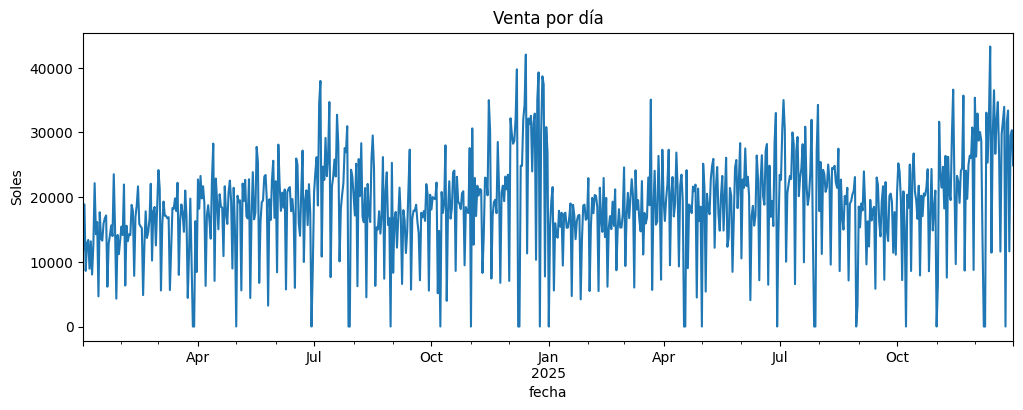

In [3]:
serie.plot(title="Venta por día", ylabel="Soles", figsize=(12, 4))
plt.show()

Se ve mucho ruido y unos picos. Agrupando se ve mejor.

### Paso 2: los patrones

In [4]:
por_dia = serie.groupby(serie.index.dayofweek).mean().round(0)
por_mes = serie.groupby(serie.index.month).mean().round(0)

print(por_dia)
print(por_mes)

fecha
0    19884.0
1    19788.0
2    18672.0
3    19332.0
4    21612.0
5    23362.0
6     7579.0
Name: total, dtype: float64
fecha
1     14182.0
2     15740.0
3     16510.0
4     17886.0
5     18380.0
6     18530.0
7     22417.0
8     18443.0
9     16365.0
10    18114.0
11    20518.0
12    25847.0
Name: total, dtype: float64


En `dayofweek`, 0 es lunes y 6 es domingo. El domingo se vende mucho menos, y el sábado más. Julio y diciembre destacan, como ya sabes. A esto se le llama **estacionalidad**.

Y los feriados valen cero, porque no hay despachos. Es información que conoces con años de anticipación. Sería absurdo que un pronóstico la ignore.

### Paso 3: tres pronósticos para noviembre

Hoy es 31 de octubre de 2025. La función lista usa solo lo anterior y pronostica cada día de noviembre de tres formas:

- **`ocho_semanas`:** el promedio de ese día de la semana en las últimas 8 semanas.
- **`regla`:** lo anterior, multiplicado por el índice: cuánto subió noviembre en 2024 frente a sus 8 semanas previas. Se parece al índice del 1.5, pero se compara con esas 8 semanas, porque de ahí parte el promedio.
- **`regresion`:** una regresión lineal con una columna por día de la semana, una por mes, y la **tendencia**, que cuenta los días desde el inicio. Así capta que la empresa crece.

En los tres, el feriado vale cero. Son funciones largas: no hace falta memorizarlas. La lista de feriados es la de estos datos: es simplificada, y una empresa real debe usar la oficial.

In [5]:
FERIADOS = pd.to_datetime(
    [
        "2024-01-01",
        "2024-03-28",
        "2024-03-29",
        "2024-05-01",
        "2024-06-29",
        "2024-07-28",
        "2024-07-29",
        "2024-08-30",
        "2024-10-08",
        "2024-11-01",
        "2024-12-08",
        "2024-12-09",
        "2024-12-25",
        "2025-01-01",
        "2025-04-17",
        "2025-04-18",
        "2025-05-01",
        "2025-06-29",
        "2025-07-28",
        "2025-07-29",
        "2025-08-30",
        "2025-10-08",
        "2025-11-01",
        "2025-12-08",
        "2025-12-09",
        "2025-12-25",
    ]
)

In [6]:
def calendario(dias):
    """Una columna por día de la semana y por mes, más la tendencia: los días desde el inicio."""
    x = pd.DataFrame(index=dias)
    for dia in range(7):
        x[f"dia_{dia}"] = (dias.dayofweek == dia).astype(int)
    for mes in range(1, 13):
        x[f"mes_{mes}"] = (dias.month == mes).astype(int)
    x["tendencia"] = (dias - pd.Timestamp("2024-01-01")).days
    return x

In [7]:
def tres_pronosticos(serie, feriados, mes):
    """Pronostica cada día de un mes con tres métodos, usando solo lo anterior a ese mes."""
    inicio = pd.Timestamp(mes + "-01")
    dias = pd.date_range(inicio, inicio + pd.offsets.MonthEnd(0))
    antes = serie[serie.index < inicio]
    laborables = antes[~antes.index.isin(feriados)]

    # Promedio por día de la semana de las últimas 8 semanas.
    ultimas = laborables[laborables.index >= inicio - pd.Timedelta(days=56)]
    por_dia = ultimas.groupby(ultimas.index.dayofweek).mean()
    ocho_semanas = pd.Series(dias.dayofweek.map(por_dia), index=dias)

    # Índice: cuánto subió ese mes en 2024 frente a las 8 semanas previas de 2024.
    hace_un_anio = inicio - pd.Timedelta(days=364)
    base = laborables[
        (laborables.index >= hace_un_anio - pd.Timedelta(days=56))
        & (laborables.index < hace_un_anio)
    ]
    mismo_mes = laborables[
        (laborables.index.year == 2024) & (laborables.index.month == inicio.month)
    ]
    regla = ocho_semanas * mismo_mes.mean() / base.mean()

    modelo = LinearRegression().fit(calendario(laborables.index), laborables)
    regresion = pd.Series(modelo.predict(calendario(dias)), index=dias)

    # Todos los métodos ponen los feriados en cero: esos días no se vende.
    tabla = pd.DataFrame(
        {"real": serie[dias], "ocho_semanas": ocho_semanas, "regla": regla, "regresion": regresion}
    )
    metodos = ["ocho_semanas", "regla", "regresion"]
    tabla.loc[tabla.index.isin(feriados), metodos] = 0
    return tabla

In [8]:
noviembre = tres_pronosticos(serie, FERIADOS, "2025-11")

noviembre.head(7).round(0)

,real,ocho_semanas,regla,regresion
2025-11-01,0.0,0.0,0.0,0.0
2025-11-02,6628.0,8286.0,9686.0,10137.0
2025-11-03,31655.0,20129.0,23531.0,22536.0
2025-11-04,23400.0,17972.0,21009.0,22220.0
2025-11-05,21466.0,18010.0,21054.0,21238.0
2025-11-06,24688.0,19276.0,22534.0,22025.0
2025-11-07,18248.0,19917.0,23284.0,24369.0


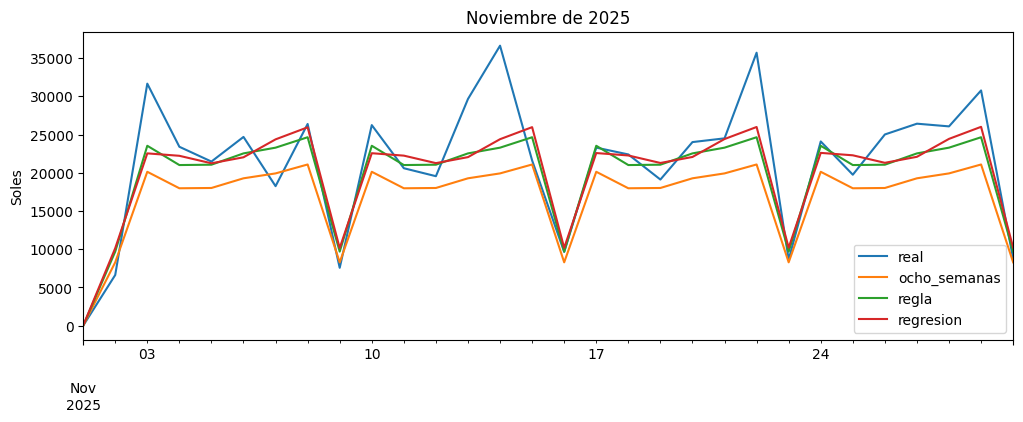

In [9]:
noviembre.plot(title="Noviembre de 2025", ylabel="Soles", figsize=(12, 4))
plt.show()

### Paso 4: cuánto se equivoca cada uno

Usamos el error medio en soles del 1.3: una columna con `=ABS()` de la diferencia, y luego `=PROMEDIO()` (`AVERAGE`). Agregamos un promedio plano de las 8 semanas, sin separar por día de la semana, para ver cuánto ayuda el calendario.

In [10]:
antes = serie["2025-09-06":"2025-10-31"]
plano = antes[~antes.index.isin(FERIADOS)].mean()
plano_noviembre = pd.Series(plano, index=noviembre.index).where(~noviembre.index.isin(FERIADOS), 0)

print("plano", round((noviembre["real"] - plano_noviembre).abs().mean()))
for metodo in ["ocho_semanas", "regla", "regresion"]:
    print(metodo, round((noviembre["real"] - noviembre[metodo]).abs().mean()))

plano 7388
ocho_semanas 4787
regla 3035
regresion 3128


El promedio plano es el peor. Separar por día de la semana ya ayuda mucho, y el índice ayuda más, porque noviembre vende más que septiembre y octubre. **La regla con índice y la regresión quedan a la par.** Una fórmula de Excel compite con una regresión. Es el mismo mensaje del 1.5: lo que ayuda es el calendario.

Pero eso es un solo mes. ¿Y si tuvimos suerte? Esa es la pregunta del próximo episodio.

> ⚠️ **Datos sintéticos.** Los patrones están programados en `catalogos.py`.

## 🤖 Pídeselo a la IA

> *"Quiero pronosticar la venta diaria de mi empresa en Excel. Tengo 2 años de datos. Explícame cómo armar un promedio por día de la semana, con un índice por mes y los feriados en cero, en español y con los nombres de las funciones en inglés."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| Una fila por día | `.groupby("fecha")["total"].sum().asfreq("D", fill_value=0)` |
| `=PROMEDIO.SI()` (`AVERAGEIF`) por día de la semana | `serie.groupby(serie.index.dayofweek).mean()` |
| Una regla con índice | `tres_pronosticos(serie, FERIADOS, mes)` |
| Comparar con lo real | `(real - pronostico).abs().mean()` |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/04-series-de-tiempo/ejercicio.ipynb) y pronostica otro mes. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-2/04-series-de-tiempo/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0